# 01 — Data Audit

Goal: understand what we actually have before modeling anything.

- Spotify Tracks Dataset (114k tracks, audio features + genre + popularity) — item metadata, no user data.
- LastFM-1K (~1K users, 16.9M track-level listening events, timestamped) — implicit feedback, no Spotify track IDs.

The two datasets share no common ID, so attaching audio features to listening events requires a **name-based join** (artist + track name). That join is lossy by construction (remixes, live versions, "feat." credits, typos won't match) — the coverage rate is a genuine finding, reported here honestly rather than glossed over.

In [1]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("seaborn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])

import seaborn as sns
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt


from src.data_loading import load_spotify_tracks, load_lastfm_1k, build_joined_interactions, AUDIO_FEATURES

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## Spotify Tracks Dataset

In [2]:
tracks = load_spotify_tracks()
print(f"{len(tracks):,} unique (artist, track) rows after dedup")
print(f"{tracks['track_genre'].nunique()} genres, {tracks['primary_artist'].nunique():,} unique primary artists")
tracks[AUDIO_FEATURES + ['popularity']].describe().T

77,134 unique (artist, track) rows after dedup
114 genres, 17,489 unique primary artists


,count,mean,std,min,25%,50%,75%,max
danceability,77134.0,0.560257,0.179246,0.000,0.44600,0.575000,0.69300,0.985
energy,77134.0,0.638108,0.258497,0.000,0.46200,0.682000,0.85800,1.000
key,77134.0,5.290663,3.558121,0.000,2.00000,5.000000,8.00000,11.000
loudness,77134.0,-8.614269,5.342587,-49.531,-10.45475,-7.256000,-5.14525,4.532
mode,77134.0,0.631434,0.482419,0.000,0.00000,1.000000,1.00000,1.000
speechiness,77134.0,0.090572,0.118682,0.000,0.03640,0.049800,0.08910,0.965
acousticness,77134.0,0.324752,0.338810,0.000,0.01460,0.182000,0.62000,0.996
instrumentalness,77134.0,0.191755,0.336261,0.000,0.00000,0.000112,0.19600,1.000
liveness,77134.0,0.220890,0.200039,0.000,0.09850,0.133000,0.28400,1.000
valence,77134.0,0.463624,0.265182,0.000,0.23900,0.450000,0.67875,0.995


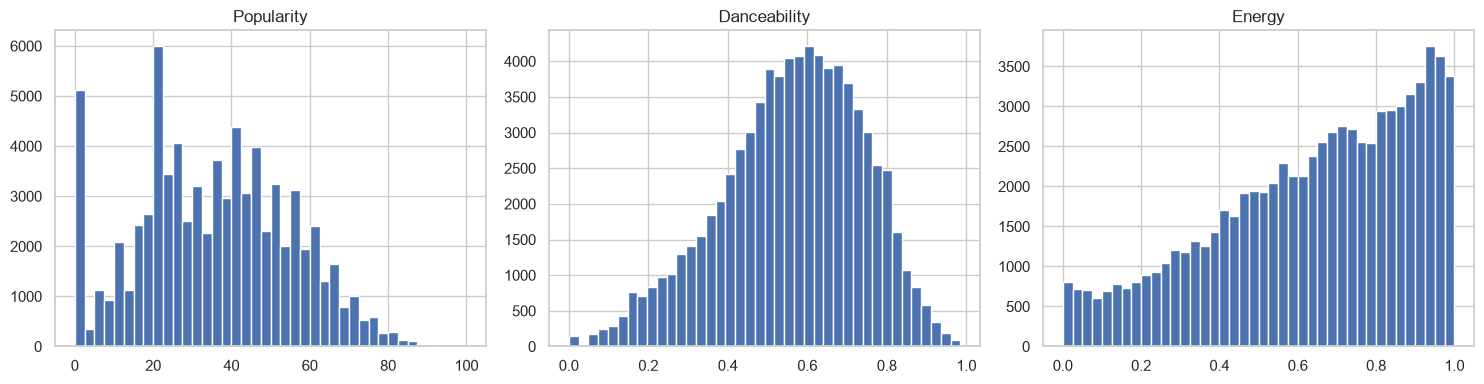

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tracks['popularity'].hist(bins=40, ax=axes[0]); axes[0].set_title('Popularity')
tracks['danceability'].hist(bins=40, ax=axes[1]); axes[1].set_title('Danceability')
tracks['energy'].hist(bins=40, ax=axes[2]); axes[2].set_title('Energy')
plt.tight_layout()
plt.savefig('../reports/figures/01_feature_distributions.png', dpi=150)
plt.show()

## LastFM-1K listening events

In [ ]:
interactions = load_lastfm_1k('train')
print(f"{len(interactions):,} events, {interactions['user_id'].nunique():,} users, {interactions['join_key'].nunique():,} unique tracks")
print(f"date range: {interactions['timestamp'].min()} to {interactions['timestamp'].max()}")
events_per_user = interactions.groupby('user_id').size()
events_per_user.describe()

In [ ]:
events_per_user.hist(bins=50, figsize=(8, 4))
plt.title('Events per user (LastFM-1K, train split)')
plt.xlabel('# listening events'); plt.ylabel('# users')
plt.savefig('../reports/figures/01_events_per_user.png', dpi=150)
plt.show()

## The join: how much of the interaction data can we actually enrich with audio features?

This is the central data-quality question of the whole project — if coverage is too low, the collaborative and content-based layers can't be meaningfully connected for the hybrid.

In [ ]:
joined, coverage = build_joined_interactions(interactions, tracks)
coverage

In [ ]:
import json
with open('../reports/figures/join_coverage.json', 'w') as f:
    json.dump(coverage, f, indent=2)
print('saved join coverage stats for use in the case study report')

## Why is track-level coverage so much lower than artist-level coverage?

Before treating the join coverage number as a finding, rule out a join bug: compare
artist-only overlap (ignoring track name) against the track-level number above. If
artist overlap is much higher, that points to a real cause (the Spotify Tracks Dataset
doesn't cover every track per artist) rather than a broken match.

In [ ]:
spotify_artists = set(tracks['primary_artist'].str.lower().str.strip())
lastfm_artists = set(interactions['artist_name'].str.lower().str.strip().dropna())
artist_overlap = spotify_artists & lastfm_artists

print(f"Spotify unique artists: {len(spotify_artists):,}")
print(f"LastFM unique artists: {len(lastfm_artists):,}")
print(
    f"Artist-name overlap: {len(artist_overlap):,} "
    f"({100 * len(artist_overlap) / len(lastfm_artists):.2f}% of LastFM artists)"
)
print(f"\nFor comparison, unique-TRACK coverage was only {coverage['unique_track_coverage_pct']}%.")
print(
    "Artist overlap being much higher confirms this isn't a join bug: the Spotify "
    "Tracks Dataset is a curated ~114k-track sample (genre-queried), not an exhaustive "
    "catalog, so even when an artist is present, the specific tracks a LastFM-1K user "
    "played in 2008-2009 rarely happen to be among the tracks sampled for that artist. "
    "Temporal mismatch (2008-2009 listening vs. a modern snapshot) compounds this further."
)

## Genre distribution among matched interactions

What genres actually survived the join? If it's skewed toward mainstream/Western pop, that's a real limitation to disclose (LastFM-1K is a 2008-era, largely Western userbase; Spotify's genre-tagged catalog reflects modern streaming — the overlap is not a random sample of either).

In [ ]:
genre_counts = joined['track_genre'].value_counts().head(20)
genre_counts.plot(kind='barh', figsize=(8, 6))
plt.title('Top 20 genres among matched interactions')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/01_genre_distribution.png', dpi=150)
plt.show()

In [ ]:
joined.to_parquet('../data/raw/interactions/joined_train.parquet')
print(f'saved {len(joined):,} joined interaction rows for downstream notebooks')